# Analisi Adattiva di Motifs e Discords

Questo notebook implementa un'analisi avanzata tramite Matrix Profile. Tutti i parametri fondamentali sono centralizzati nella **Cella di Configurazione** per permettere un adattamento dinamico dell'intera pipeline.


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import stumpy
from sklearn.cluster import KMeans
from sktime.clustering.k_means import TimeSeriesKMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

try:
    from tslearn.shapelets import ShapeletModel
    from tslearn.utils import to_time_series_dataset
except ImportError:
    print("tslearn non trovata. Puoi installarla con !pip install tslearn")

import warnings
warnings.filterwarnings('ignore')

print("Caricamento dataset normalizzato (Instance-wise)...")
ts_data = pd.read_pickle('ts_normalized.pkl.gz')
print(f"Trovate {len(ts_data)} serie storiche.")


tslearn non trovata. Puoi installarla con !pip install tslearn
Caricamento dataset normalizzato (Instance-wise)...
Trovate 4437 serie storiche.


## Pannello di Configurazione Globale
Modifica liberamente i parametri in questa cella. Tutto il codice, le estrazioni, i plot e le etichette si adatteranno in automatico!


In [17]:
# --- CONFIGURAZIONE GLOBALE ---
m = 8                          # Window size (es. 16 campionamenti = 8 ore se step=30min)
target_features = ['enmo', 'anglez']         # Variabile su cui calcolare il Matrix Profile (es. 'enmo', 'anglez', 'light')

k_clusters_motif = 3            # Numero di cluster desiderati per l'analisi dei Motif DTW
k_clusters_multi = 3            # Numero di cluster per l'analisi Multivariata Dataset-wise

top_k_motifs = 2                # Quanti Motif estrarre per ogni time series
top_k_discords = 2              # Quanti Discord estrarre per ogni time series

n_shapelets = 3                 # Numero di Shapelet da estrarre

# Variabile di supporto per stampare le etichette di tempo automaticamente
h_str = f"{m/2:g} ore"
print("Parametri configurati correttamente!")
subset_ts = ts_data#[:200] 


Parametri configurati correttamente!


## Strategia A: Analisi sui Medoidi
Applichiamo il Matrix Profile sui medoidi pre-calcolati dal clustering globale. Questo estrae e visualizza i pattern più frequenti e le anomalie sui prototipi dei bambini.



ANALISI SULLA FEATURE: enmo


--- ANALISI DEL MEDOIDE 1452 (enmo) ---
I Top-2 Motifs sono stati trovati. Esempio Top-1 agli indici: [np.int64(68), np.int64(131), 142]
   -> Questo significa che i blocchi di 4 ore che iniziano a questi step sono risultati quasi identici (routine).
I Top-2 Discords sono stati trovati agli indici: [163 189]
   -> Le finestre di 4 ore che iniziano a questi step sono le più uniche e anomale del tracciato.



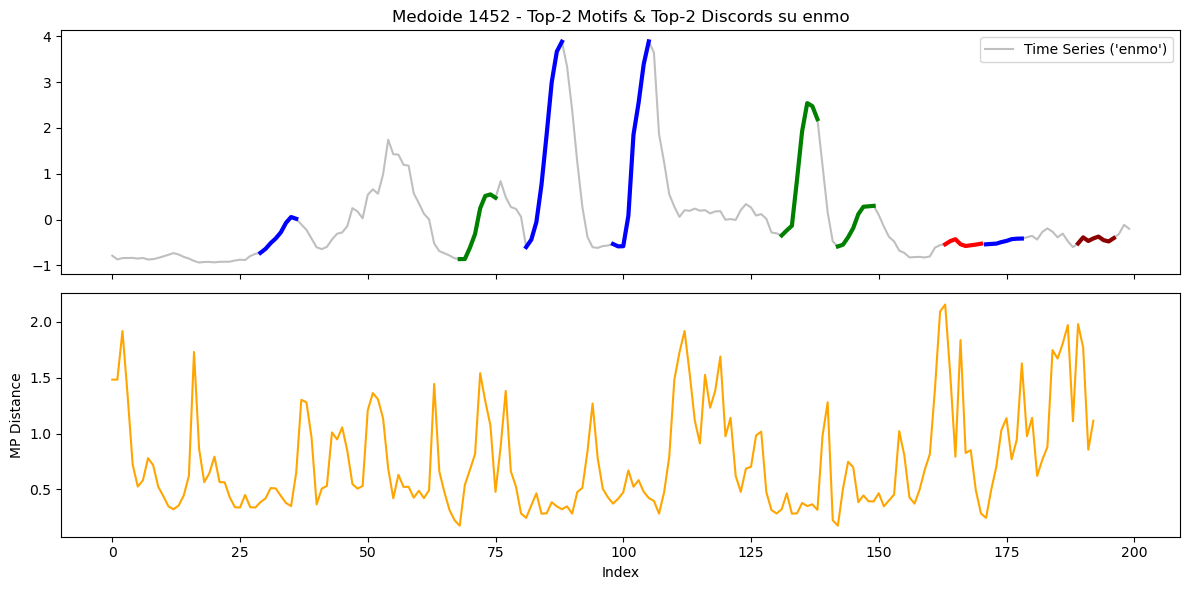


--- ANALISI DEL MEDOIDE 2791 (enmo) ---
I Top-2 Motifs sono stati trovati. Esempio Top-1 agli indici: [np.int64(53), 71]
   -> Questo significa che i blocchi di 4 ore che iniziano a questi step sono risultati quasi identici (routine).
I Top-2 Discords sono stati trovati agli indici: [153   0]
   -> Le finestre di 4 ore che iniziano a questi step sono le più uniche e anomale del tracciato.



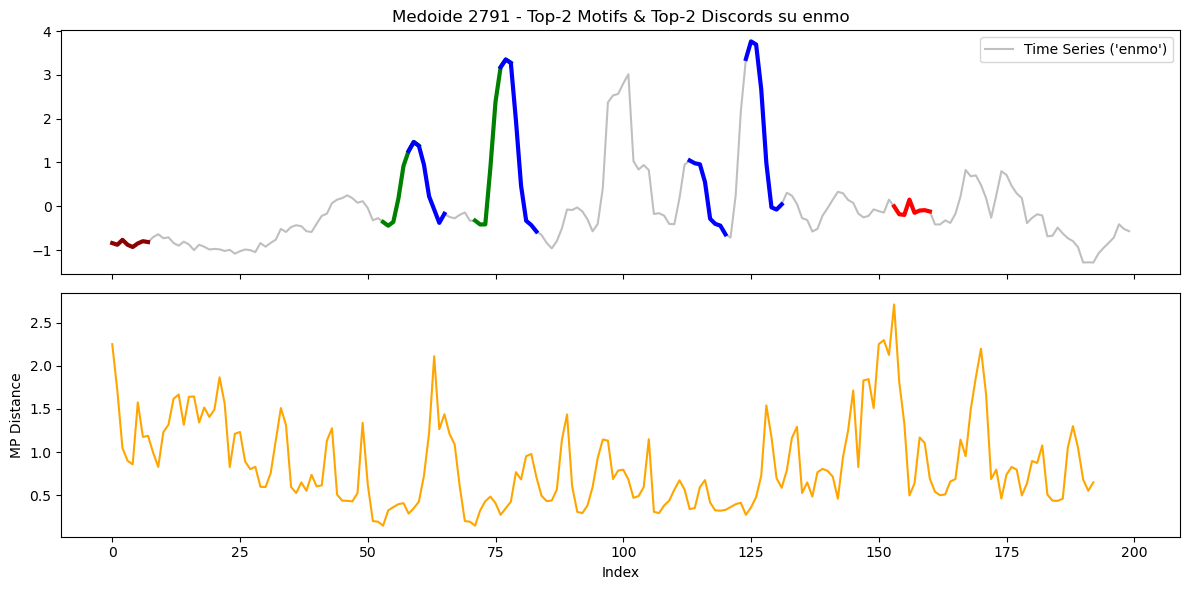


--- ANALISI DEL MEDOIDE 2734 (enmo) ---
I Top-1 Motifs sono stati trovati. Esempio Top-1 agli indici: [np.int64(33), np.int64(90), np.int64(110), np.int64(130), 153, np.int64(172)]
   -> Questo significa che i blocchi di 4 ore che iniziano a questi step sono risultati quasi identici (routine).
I Top-2 Discords sono stati trovati agli indici: [  0 191]
   -> Le finestre di 4 ore che iniziano a questi step sono le più uniche e anomale del tracciato.



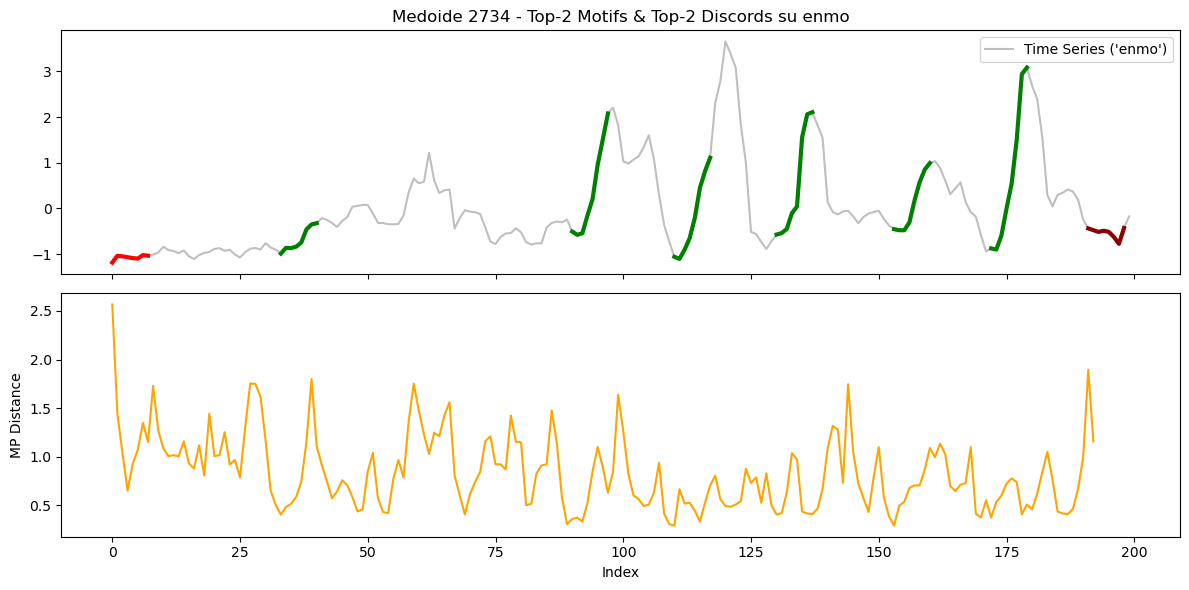


--- ANALISI DEL MEDOIDE 311 (enmo) ---
I Top-2 Motifs sono stati trovati. Esempio Top-1 agli indici: [np.int64(119), 147]
   -> Questo significa che i blocchi di 4 ore che iniziano a questi step sono risultati quasi identici (routine).
I Top-2 Discords sono stati trovati agli indici: [ 50 129]
   -> Le finestre di 4 ore che iniziano a questi step sono le più uniche e anomale del tracciato.



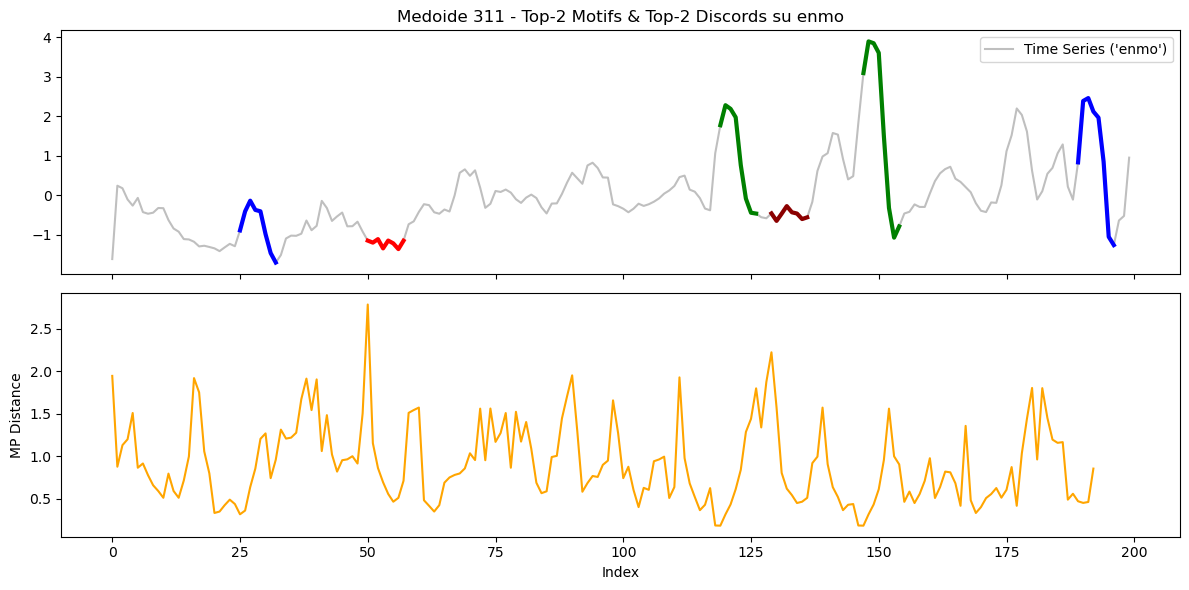


ANALISI SULLA FEATURE: anglez


--- ANALISI DEL MEDOIDE 1452 (anglez) ---
I Top-2 Motifs sono stati trovati. Esempio Top-1 agli indici: [np.int64(93), 181]
   -> Questo significa che i blocchi di 4 ore che iniziano a questi step sono risultati quasi identici (routine).
I Top-2 Discords sono stati trovati agli indici: [64 59]
   -> Le finestre di 4 ore che iniziano a questi step sono le più uniche e anomale del tracciato.



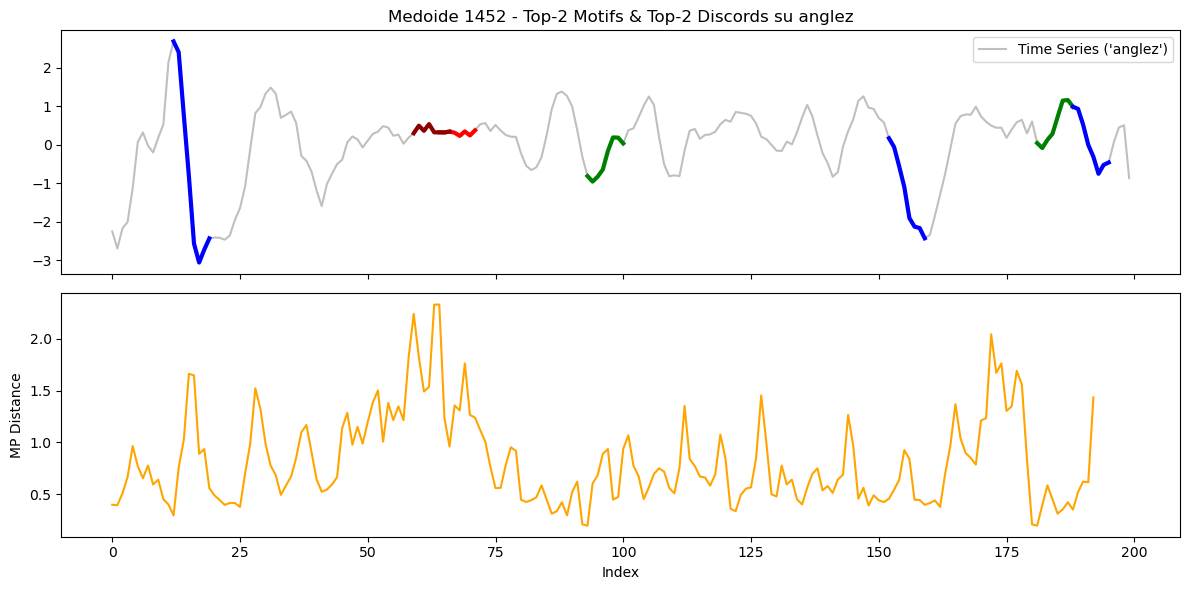


--- ANALISI DEL MEDOIDE 2791 (anglez) ---
I Top-2 Motifs sono stati trovati. Esempio Top-1 agli indici: [np.int64(44), 57, np.int64(77)]
   -> Questo significa che i blocchi di 4 ore che iniziano a questi step sono risultati quasi identici (routine).
I Top-2 Discords sono stati trovati agli indici: [168 102]
   -> Le finestre di 4 ore che iniziano a questi step sono le più uniche e anomale del tracciato.



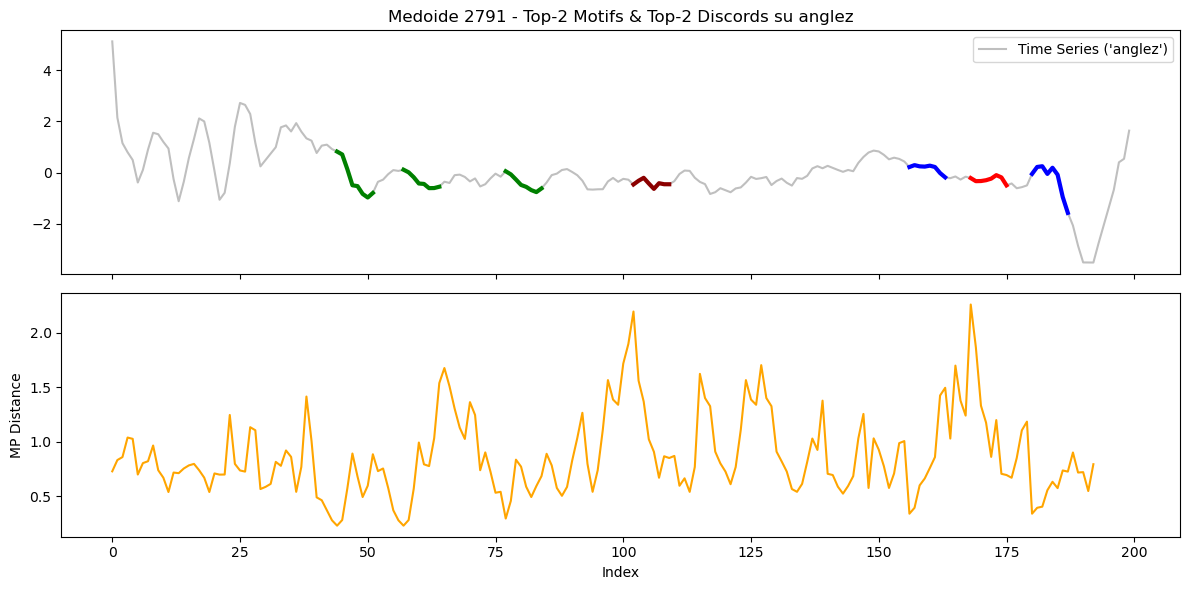


--- ANALISI DEL MEDOIDE 2734 (anglez) ---
I Top-2 Motifs sono stati trovati. Esempio Top-1 agli indici: [np.int64(41), 191]
   -> Questo significa che i blocchi di 4 ore che iniziano a questi step sono risultati quasi identici (routine).
I Top-2 Discords sono stati trovati agli indici: [183 145]
   -> Le finestre di 4 ore che iniziano a questi step sono le più uniche e anomale del tracciato.



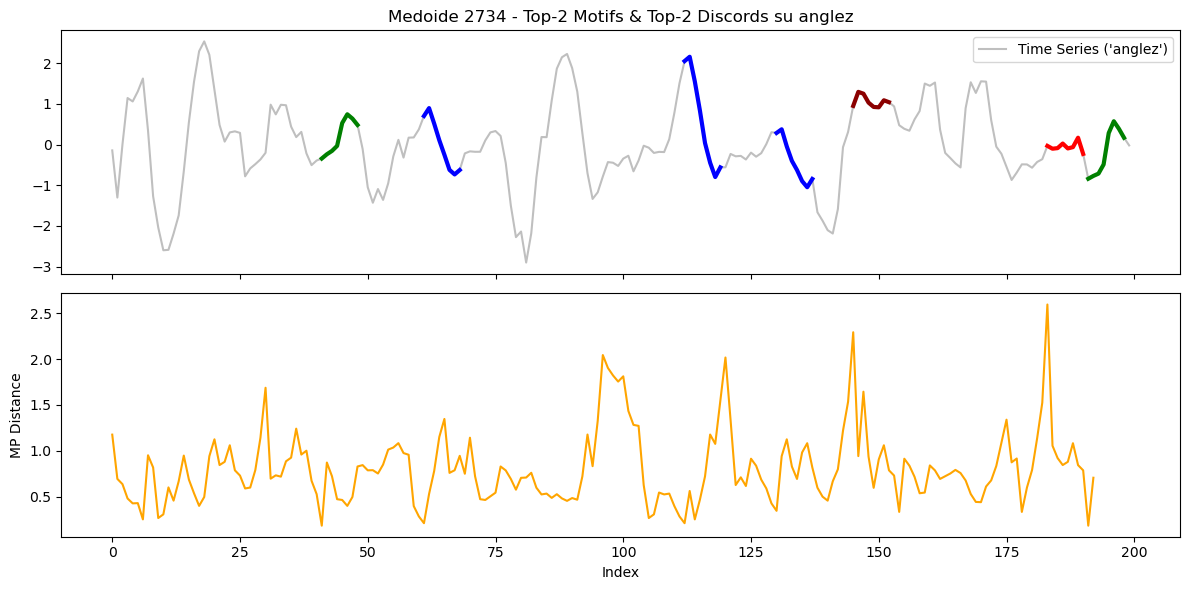


--- ANALISI DEL MEDOIDE 311 (anglez) ---
I Top-2 Motifs sono stati trovati. Esempio Top-1 agli indici: [np.int64(13), 113]
   -> Questo significa che i blocchi di 4 ore che iniziano a questi step sono risultati quasi identici (routine).
I Top-2 Discords sono stati trovati agli indici: [148 132]
   -> Le finestre di 4 ore che iniziano a questi step sono le più uniche e anomale del tracciato.



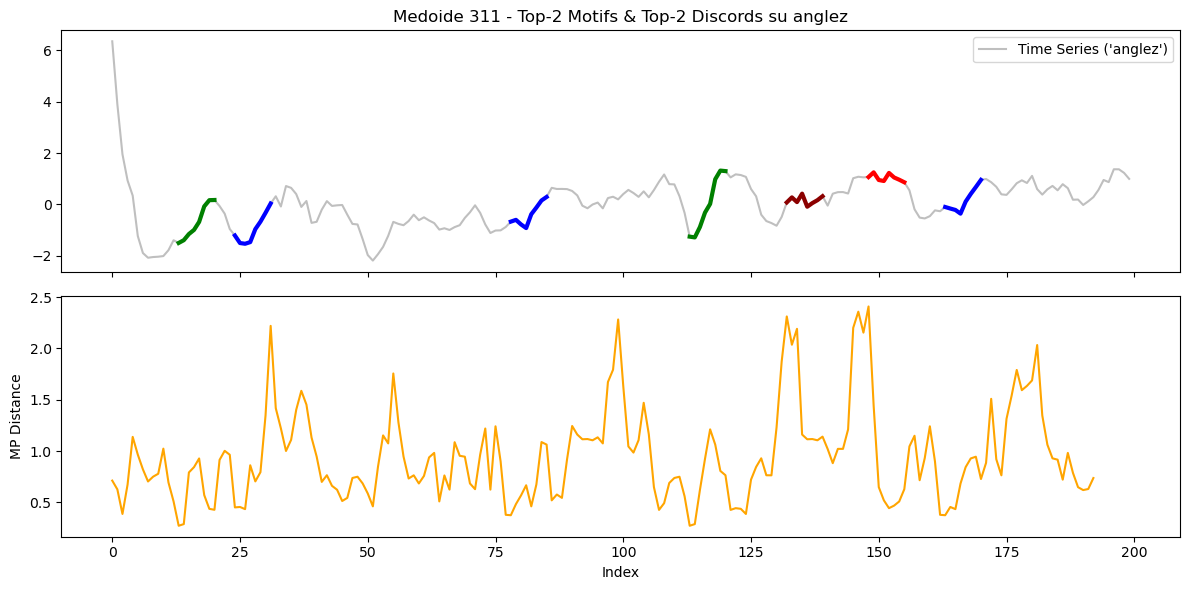

In [13]:
from matrixprofile import motifs
from matrixprofile.discords import discords

medoid_idx = [1452, 2791, 2734, 311]
medoids = [ts_data[i] for i in medoid_idx]

for target_feature in target_features:
    print(f"\n{'='*50}\nANALISI SULLA FEATURE: {target_feature}\n{'='*50}\n")
    
    for i, ts_df in enumerate(medoids):
        ts_medoide = ts_df[target_feature].values.astype(np.float64)

        # Calcoliamo il MP con stumpy per avere la matrice base
        mp_full = stumpy.stump(ts_medoide, m)
        mp_dist = mp_full[:, 0].astype(np.float64)
        mpi = mp_full[:, 1].astype(np.int64)

        # Estrattore Motifs tramite matrixprofile-ts come richiesto
        mo, mod = motifs.motifs(ts_medoide, (mp_dist, mpi), max_motifs=top_k_motifs)
        
        # Estrattore Discords tramite matrixprofile-ts come richiesto
        anoms = discords(mp_dist, ex_zone=int(m/2), k=top_k_discords)

        print(f"\n--- ANALISI DEL MEDOIDE {medoid_idx[i]} ({target_feature}) ---")
        if len(mo) > 0:
            print(f"I Top-{len(mo)} Motifs sono stati trovati. Esempio Top-1 agli indici: {mo[0]}")
            print(f"   -> Questo significa che i blocchi di {h_str} che iniziano a questi step sono risultati quasi identici (routine).")
        
        if len(anoms) > 0:
            print(f"I Top-{len(anoms)} Discords sono stati trovati agli indici: {anoms}")
            print(f"   -> Le finestre di {h_str} che iniziano a questi step sono le più uniche e anomale del tracciato.\n")

        # Configurazione struttura subplots originale: 1 per le TS con Motifs/Discords, 1 per il Matrix Profile
        fig, axs = plt.subplots(2, 1, sharex=True, figsize=(12, 6))
        
        # PLOT DEI MOTIFS E DISCORDS INSIEME
        axs[0].plot(ts_medoide, label=f"Time Series ('{target_feature}')", color='gray', alpha=0.5)
        axs[0].set_title(f"Medoide {medoid_idx[i]} - Top-{top_k_motifs} Motifs & Top-{top_k_discords} Discords su {target_feature}")
        
        # Plot Motifs
        colors_mo = ['g', 'b', 'm', 'c', 'y'][:max(1, len(mo))]
        for motif_group, d, c in zip(mo, mod, colors_mo):
            for idx in motif_group:
                m_shape = ts_medoide[idx : idx + m]
                axs[0].plot(range(idx, idx + m), m_shape, color=c, lw=3)
                
        # Plot Discords (in rosso)
        colors_anom = ['r', 'darkred', 'salmon', 'orange', 'k'][:max(1, len(anoms))]
        for a, c in zip(anoms, colors_anom):
            a_shape = ts_medoide[a : a + m]
            axs[0].plot(range(a, a + m), a_shape, color=c, lw=3)
            
        axs[0].legend(loc='upper right')

        # PLOT DELLA MATRIX PROFILE DISTANCE (Valli e Picchi)
        axs[1].plot(mp_dist, color='orange')
        axs[1].set_ylabel('MP Distance')
        axs[1].set_xlabel('Index')
        
        plt.tight_layout()
        plt.show()


## Clustering Multivariato Dataset-wise
Qui incrociamo il Motif con le *altre variabili* del dataset grezzo (intensità assolute) per creare un cluster basato sul contesto.


Caricamento dataset normalizzato dataset-wise...
Estrazione contesto multivariato ancorato sui Motif trovati su 'enmo'...

Esecuzione KMeans Multivariato (K=3)...

--- PROFILO DEI CLUSTER: MEDIE NUMERICHE E DISTRIBUZIONI CATEGORICHE ---


,enmo_mean,anglez_mean,light_mean,X_mean,Y_mean,Z_mean,sii_binary,weekday_mode_1,weekday_mode_2,weekday_mode_3,weekday_mode_4,weekday_mode_5,weekday_mode_6,weekday_mode_7,quarter_mode_1,quarter_mode_2,quarter_mode_3,quarter_mode_4,sii_binary_mean
Cluster_Multivariato,,,,,,,,,,,,,,,,,,,
0,0.000401,-0.399440,0.309297,-0.739704,-0.065034,-0.399985,0.345673,0.138825,0.142989,0.146229,0.139750,0.152244,0.139750,0.140213,0.256826,0.268394,0.193429,0.281351,0.345673
1,0.078762,-0.269760,0.308802,1.132106,0.036228,-0.287167,0.287538,0.131381,0.148649,0.139640,0.148649,0.156156,0.138889,0.136637,0.213213,0.303303,0.213964,0.269520,0.287538
2,-0.163268,1.307885,0.276246,0.063032,-0.049556,1.356241,0.370763,0.148305,0.134534,0.144068,0.152542,0.138771,0.155720,0.126059,0.291314,0.268008,0.217161,0.223517,0.370763



--- INTERPRETAZIONE DEI CLUSTER MULTIVARIATI ---
- Cluster 1:
   * Attività media (enmo norm.): 0.0004
   * Inclinazione media polso (anglez norm.): -0.40
   * Luce ambientale media (norm.): 0.309
   * Giorno predominante: Giorno 5 (15.2%)
   * Stagione predominante: Quarter 4 (28.1%)
   * Correlazione con Problematic Internet Use: 34.6% di casi problematici.
- Cluster 2:
   * Attività media (enmo norm.): 0.0788
   * Inclinazione media polso (anglez norm.): -0.27
   * Luce ambientale media (norm.): 0.309
   * Giorno predominante: Giorno 5 (15.6%)
   * Stagione predominante: Quarter 2 (30.3%)
   * Correlazione con Problematic Internet Use: 28.8% di casi problematici.
- Cluster 3:
   * Attività media (enmo norm.): -0.1633
   * Inclinazione media polso (anglez norm.): 1.31
   * Luce ambientale media (norm.): 0.276
   * Giorno predominante: Giorno 6 (15.6%)
   * Stagione predominante: Quarter 1 (29.1%)
   * Correlazione con Problematic Internet Use: 37.1% di casi problematici.

Generazion

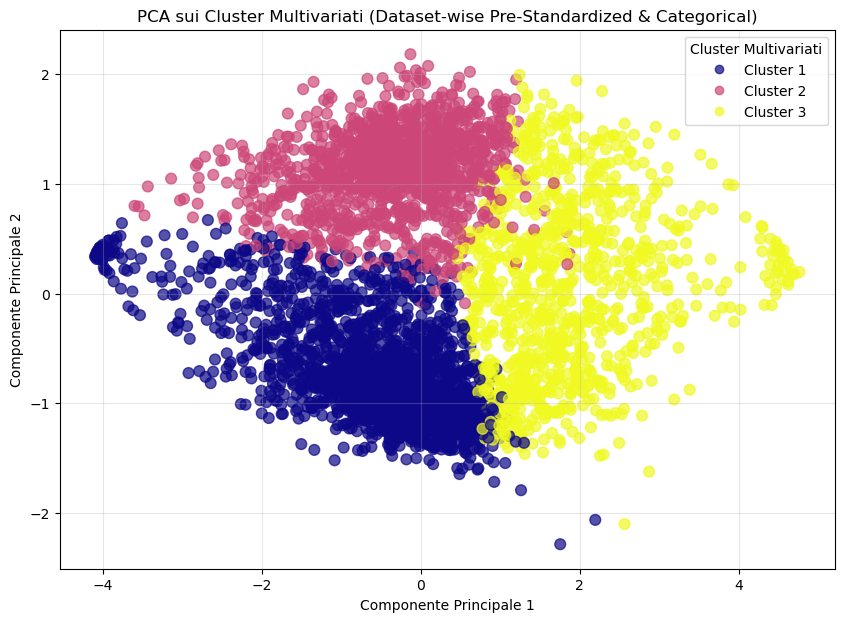

"numeric_cols = ['enmo_mean', 'anglez_mean', 'light_mean', 'X_mean', 'Y_mean', 'Z_mean']\nfig, axs = plt.subplots(len(numeric_cols), 1, figsize=(10, 12), sharex=True)\nfor j, col in enumerate(numeric_cols):\n    cluster_profiles[col].plot(kind='bar', ax=axs[j], color='darkorange', alpha=0.8)\n    axs[j].set_title(f'Media normalizzata {col} per Cluster')\n    axs[j].grid(True, alpha=0.3)\nplt.tight_layout()\nplt.show()"

In [18]:
from IPython.display import display

print("Caricamento dataset normalizzato dataset-wise...")
# CARICHIAMO IL NUOVO DATASET GIA' NORMALIZZATO
ts_raw_data = pd.read_pickle('ts_datasetwise_normalized.pkl.gz')

motif_features_list = []

# Usiamo la prima feature della lista come ancora temporale
anchor_feature = target_features[0]
print(f"Estrazione contesto multivariato ancorato sui Motif trovati su '{anchor_feature}'...")

for i, ts_df in enumerate(subset_ts):
    ts_val = ts_df[anchor_feature].values.astype(np.float64)
    if len(ts_val) <= m: continue
        
    mp_local = stumpy.stump(ts_val, m)
    # Estraiamo il primo motif
    m_idx = np.argmin(mp_local[:, 0])
    
    motif_raw_df = ts_raw_data[i].iloc[m_idx : m_idx + m]
    
    features = {
        'enmo_mean': motif_raw_df['enmo'].mean(),
        'anglez_mean': motif_raw_df['anglez'].mean(),
        'light_mean': motif_raw_df['light'].mean(),
        'X_mean': motif_raw_df['X'].mean(),
        'Y_mean': motif_raw_df['Y'].mean(),
        'Z_mean': motif_raw_df['Z'].mean(),
        'weekday_mode': str(int(motif_raw_df['weekday'].mode().iloc[0])),
        'quarter_mode': str(int(motif_raw_df['quarter'].mode().iloc[0])), # Variabile Fissa
        'sii_binary': motif_raw_df['sii_binary'].iloc[0] # Variabile Target (NON usata per clustering)
    }
    motif_features_list.append(features)

df_motif_features = pd.DataFrame(motif_features_list)
# Dummy per le variabili categoriche/fisse (Queste VENGONO usate nel clustering!)
df_motif_encoded = pd.get_dummies(df_motif_features, columns=['weekday_mode', 'quarter_mode'])

cols_to_drop = ['sii_binary']
X_cluster = df_motif_encoded.drop(columns=cols_to_drop)

# NON USIAMO PIU' STANDARD SCALER QUI
# I dati sono già stati standardizzati globalmente in preprocessing!
X_cluster = X_cluster.astype(float)

print(f"\nEsecuzione KMeans Multivariato (K={k_clusters_multi})...")
kmeans_multi = KMeans(n_clusters=k_clusters_multi, random_state=42)
multi_clusters = kmeans_multi.fit_predict(X_cluster)

# Aggiungiamo i cluster ad entrambi i dataframe per l'analisi
df_motif_features['Cluster_Multivariato'] = multi_clusters
df_motif_encoded['Cluster_Multivariato'] = multi_clusters

print("\n--- PROFILO DEI CLUSTER: MEDIE NUMERICHE E DISTRIBUZIONI CATEGORICHE ---")
# Usiamo df_motif_encoded così vediamo le percentuali (medie) delle variabili dummy categoriche!
cluster_profiles = df_motif_encoded.groupby('Cluster_Multivariato').mean()
# Riappendiamo la target variable solo per visualizzazione post-hoc
cluster_profiles['sii_binary_mean'] = df_motif_features.groupby('Cluster_Multivariato')['sii_binary'].mean()
display(cluster_profiles)

print("\n--- INTERPRETAZIONE DEI CLUSTER MULTIVARIATI ---")
for i, row in cluster_profiles.iterrows():
    print(f"- Cluster {i+1}:")
    print(f"   * Attività media (enmo norm.): {row['enmo_mean']:.4f}")
    print(f"   * Inclinazione media polso (anglez norm.): {row['anglez_mean']:.2f}")
    print(f"   * Luce ambientale media (norm.): {row['light_mean']:.3f}")
    
    # Trova il giorno e la stagione predominanti guardando le percentuali massime delle dummy
    weekday_cols = [c for c in row.index if 'weekday_mode' in c]
    quarter_cols = [c for c in row.index if 'quarter_mode' in c]
    if weekday_cols:
        top_day = max(weekday_cols, key=lambda c: row[c])
        print(f"   * Giorno predominante: {top_day.replace('weekday_mode_', 'Giorno ')} ({row[top_day]*100:.1f}%)")
    if quarter_cols:
        top_quarter = max(quarter_cols, key=lambda c: row[c])
        print(f"   * Stagione predominante: {top_quarter.replace('quarter_mode_', 'Quarter ')} ({row[top_quarter]*100:.1f}%)")
        
    print(f"   * Correlazione con Problematic Internet Use: {row['sii_binary_mean']*100:.1f}% di casi problematici.")

# Visualizzazione PCA Multivariata
print("\nGenerazione PCA Multivariata...")
pca_multi = PCA(n_components=2)
X_pca_multi = pca_multi.fit_transform(X_cluster)
plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca_multi[:, 0], X_pca_multi[:, 1], c=multi_clusters, cmap='plasma', alpha=0.7, s=60)
handles, _ = scatter.legend_elements()
plt.legend(handles, [f"Cluster {i+1}" for i in range(k_clusters_multi)], title="Cluster Multivariati")
plt.title(f"PCA sui Cluster Multivariati (Dataset-wise Pre-Standardized & Categorical)")
plt.xlabel("Componente Principale 1")
plt.ylabel("Componente Principale 2")
plt.grid(True, alpha=0.3)
plt.show()

# Grafici a Barre (solo numeriche continue)
'''numeric_cols = ['enmo_mean', 'anglez_mean', 'light_mean', 'X_mean', 'Y_mean', 'Z_mean']
fig, axs = plt.subplots(len(numeric_cols), 1, figsize=(10, 12), sharex=True)
for j, col in enumerate(numeric_cols):
    cluster_profiles[col].plot(kind='bar', ax=axs[j], color='darkorange', alpha=0.8)
    axs[j].set_title(f'Media normalizzata {col} per Cluster')
    axs[j].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()'''


Caricamento dataset normalizzato istance-wise...
Estrazione contesto multivariato ancorato sui Motif trovati su 'enmo'...

Esecuzione KMeans Multivariato (K=3)...

--- PROFILO DEI CLUSTER: MEDIE NUMERICHE E DISTRIBUZIONI CATEGORICHE ---


,enmo_mean,anglez_mean,light_mean,X_mean,Y_mean,Z_mean,sii_binary,weekday_mode_1,weekday_mode_2,weekday_mode_3,weekday_mode_4,weekday_mode_5,weekday_mode_6,weekday_mode_7,quarter_mode_1,quarter_mode_2,quarter_mode_3,quarter_mode_4,sii_binary_mean
Cluster_Multivariato,,,,,,,,,,,,,,,,,,,
0,1.149037,0.144646,0.052543,-0.139303,-0.102582,0.164401,0.333049,0.143101,0.140545,0.151618,0.137990,0.146508,0.143952,0.136286,0.282794,0.264055,0.205281,0.247871,0.333049
1,-0.387279,-0.671624,0.013932,0.031473,-0.001245,-0.679336,0.332432,0.141081,0.149730,0.124865,0.144324,0.161081,0.133514,0.145405,0.231892,0.283784,0.195135,0.289189,0.332432
2,-0.355439,0.825994,0.014003,0.052641,-0.030368,0.814017,0.335456,0.131635,0.135881,0.162067,0.152159,0.140127,0.154282,0.123850,0.249823,0.284501,0.216561,0.249115,0.335456



--- INTERPRETAZIONE DEI CLUSTER MULTIVARIATI ---
- Cluster 1:
   * Attività media (enmo norm.): 1.1490
   * Inclinazione media polso (anglez norm.): 0.14
   * Luce ambientale media (norm.): 0.053
   * Giorno predominante: Giorno 3 (15.2%)
   * Stagione predominante: Quarter 1 (28.3%)
   * Correlazione con Problematic Internet Use: 33.3% di casi problematici.
- Cluster 2:
   * Attività media (enmo norm.): -0.3873
   * Inclinazione media polso (anglez norm.): -0.67
   * Luce ambientale media (norm.): 0.014
   * Giorno predominante: Giorno 5 (16.1%)
   * Stagione predominante: Quarter 4 (28.9%)
   * Correlazione con Problematic Internet Use: 33.2% di casi problematici.
- Cluster 3:
   * Attività media (enmo norm.): -0.3554
   * Inclinazione media polso (anglez norm.): 0.83
   * Luce ambientale media (norm.): 0.014
   * Giorno predominante: Giorno 3 (16.2%)
   * Stagione predominante: Quarter 2 (28.5%)
   * Correlazione con Problematic Internet Use: 33.5% di casi problematici.

Generazion

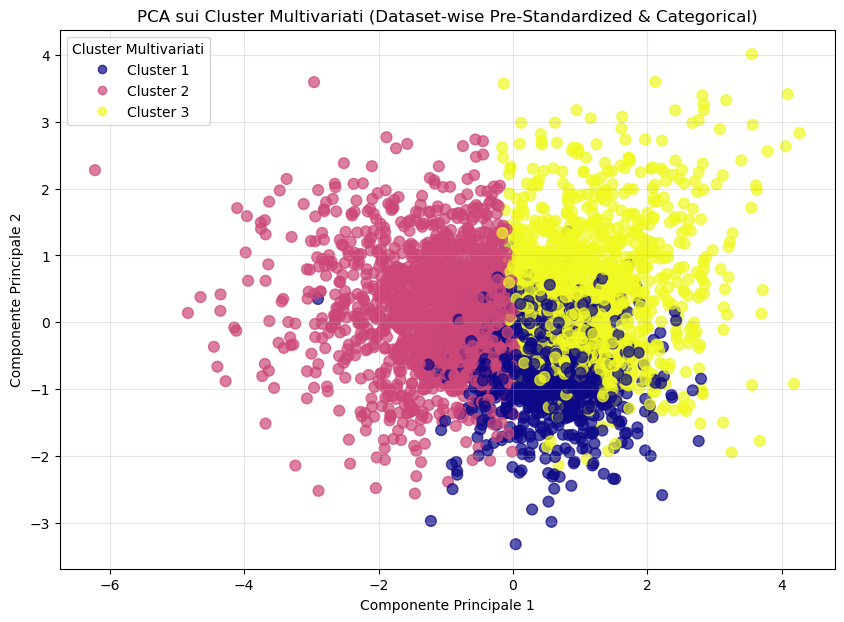

"numeric_cols = ['enmo_mean', 'anglez_mean', 'light_mean', 'X_mean', 'Y_mean', 'Z_mean']\nfig, axs = plt.subplots(len(numeric_cols), 1, figsize=(10, 12), sharex=True)\nfor j, col in enumerate(numeric_cols):\n    cluster_profiles[col].plot(kind='bar', ax=axs[j], color='darkorange', alpha=0.8)\n    axs[j].set_title(f'Media normalizzata {col} per Cluster')\n    axs[j].grid(True, alpha=0.3)\nplt.tight_layout()\nplt.show()"

In [19]:
from IPython.display import display

print("Caricamento dataset normalizzato istance-wise...")

motif_features_list = []

# Usiamo la prima feature della lista come ancora temporale
anchor_feature = target_features[0]
print(f"Estrazione contesto multivariato ancorato sui Motif trovati su '{anchor_feature}'...")

for i, ts_df in enumerate(subset_ts):
    ts_val = ts_df[anchor_feature].values.astype(np.float64)
    if len(ts_val) <= m: continue
        
    mp_local = stumpy.stump(ts_val, m)
    # Estraiamo il primo motif
    m_idx = np.argmin(mp_local[:, 0])
    
    motif_raw_df = ts_data[i].iloc[m_idx : m_idx + m]
    
    features = {
        'enmo_mean': motif_raw_df['enmo'].mean(),
        'anglez_mean': motif_raw_df['anglez'].mean(),
        'light_mean': motif_raw_df['light'].mean(),
        'X_mean': motif_raw_df['X'].mean(),
        'Y_mean': motif_raw_df['Y'].mean(),
        'Z_mean': motif_raw_df['Z'].mean(),
        'weekday_mode': str(int(motif_raw_df['weekday'].mode().iloc[0])),
        'quarter_mode': str(int(motif_raw_df['quarter'].mode().iloc[0])), # Variabile Fissa
        'sii_binary': motif_raw_df['sii_binary'].iloc[0] # Variabile Target (NON usata per clustering)
    }
    motif_features_list.append(features)

df_motif_features = pd.DataFrame(motif_features_list)
# Dummy per le variabili categoriche/fisse (Queste VENGONO usate nel clustering!)
df_motif_encoded = pd.get_dummies(df_motif_features, columns=['weekday_mode', 'quarter_mode'])

cols_to_drop = ['sii_binary']
X_cluster = df_motif_encoded.drop(columns=cols_to_drop)

# NON USIAMO PIU' STANDARD SCALER QUI
# I dati sono già stati standardizzati globalmente in preprocessing!
X_cluster = X_cluster.astype(float)

print(f"\nEsecuzione KMeans Multivariato (K={k_clusters_multi})...")
kmeans_multi = KMeans(n_clusters=k_clusters_multi, random_state=42)
multi_clusters = kmeans_multi.fit_predict(X_cluster)

# Aggiungiamo i cluster ad entrambi i dataframe per l'analisi
df_motif_features['Cluster_Multivariato'] = multi_clusters
df_motif_encoded['Cluster_Multivariato'] = multi_clusters

print("\n--- PROFILO DEI CLUSTER: MEDIE NUMERICHE E DISTRIBUZIONI CATEGORICHE ---")
# Usiamo df_motif_encoded così vediamo le percentuali (medie) delle variabili dummy categoriche!
cluster_profiles = df_motif_encoded.groupby('Cluster_Multivariato').mean()
# Riappendiamo la target variable solo per visualizzazione post-hoc
cluster_profiles['sii_binary_mean'] = df_motif_features.groupby('Cluster_Multivariato')['sii_binary'].mean()
display(cluster_profiles)

print("\n--- INTERPRETAZIONE DEI CLUSTER MULTIVARIATI ---")
for i, row in cluster_profiles.iterrows():
    print(f"- Cluster {i+1}:")
    print(f"   * Attività media (enmo norm.): {row['enmo_mean']:.4f}")
    print(f"   * Inclinazione media polso (anglez norm.): {row['anglez_mean']:.2f}")
    print(f"   * Luce ambientale media (norm.): {row['light_mean']:.3f}")
    
    # Trova il giorno e la stagione predominanti guardando le percentuali massime delle dummy
    weekday_cols = [c for c in row.index if 'weekday_mode' in c]
    quarter_cols = [c for c in row.index if 'quarter_mode' in c]
    if weekday_cols:
        top_day = max(weekday_cols, key=lambda c: row[c])
        print(f"   * Giorno predominante: {top_day.replace('weekday_mode_', 'Giorno ')} ({row[top_day]*100:.1f}%)")
    if quarter_cols:
        top_quarter = max(quarter_cols, key=lambda c: row[c])
        print(f"   * Stagione predominante: {top_quarter.replace('quarter_mode_', 'Quarter ')} ({row[top_quarter]*100:.1f}%)")
        
    print(f"   * Correlazione con Problematic Internet Use: {row['sii_binary_mean']*100:.1f}% di casi problematici.")

# Visualizzazione PCA Multivariata
print("\nGenerazione PCA Multivariata...")
pca_multi = PCA(n_components=2)
X_pca_multi = pca_multi.fit_transform(X_cluster)
plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca_multi[:, 0], X_pca_multi[:, 1], c=multi_clusters, cmap='plasma', alpha=0.7, s=60)
handles, _ = scatter.legend_elements()
plt.legend(handles, [f"Cluster {i+1}" for i in range(k_clusters_multi)], title="Cluster Multivariati")
plt.title(f"PCA sui Cluster Multivariati (Dataset-wise Pre-Standardized & Categorical)")
plt.xlabel("Componente Principale 1")
plt.ylabel("Componente Principale 2")
plt.grid(True, alpha=0.3)
plt.show()

# Grafici a Barre (solo numeriche continue)
'''numeric_cols = ['enmo_mean', 'anglez_mean', 'light_mean', 'X_mean', 'Y_mean', 'Z_mean']
fig, axs = plt.subplots(len(numeric_cols), 1, figsize=(10, 12), sharex=True)
for j, col in enumerate(numeric_cols):
    cluster_profiles[col].plot(kind='bar', ax=axs[j], color='darkorange', alpha=0.8)
    axs[j].set_title(f'Media normalizzata {col} per Cluster')
    axs[j].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()'''


## Clustering Multivariato Dataset-wise (Solo Variabili Continue)
In questa sezione ignoriamo le variabili categoriche fisse per forzare l'algoritmo a raggruppare i comportamenti basandosi esclusivamente sull'intensità quantitativa del movimento e della luce.
from IPython.display import display

Caricamento dataset normalizzato dataset-wise...
Estrazione contesto multivariato ancorato sui Motif trovati su 'enmo'...

Esecuzione KMeans Multivariato SENZA Variabili Categoriche (K=3)...

--- PROFILO DEI CLUSTER: MEDIE NUMERICHE ---


,enmo_mean,anglez_mean,light_mean,X_mean,Y_mean,Z_mean,sii_binary
Cluster_Multivariato,,,,,,,
0,0.138280,-0.130579,0.320897,-0.860462,-0.047178,-0.144652,0.344969
1,-0.114751,-0.621966,0.296304,0.875978,-0.017941,-0.619369,0.307342
2,-0.148540,1.288115,0.273023,0.312648,-0.020578,1.335167,0.352632



--- INTERPRETAZIONE DEI CLUSTER MULTIVARIATI ---
- Cluster 1:
   * Attività media (enmo norm.): 0.1383
   * Inclinazione media polso (anglez norm.): -0.13
   * Luce ambientale media (norm.): 0.321
   * Correlazione con Problematic Internet Use: 34.5% di casi problematici.
- Cluster 2:
   * Attività media (enmo norm.): -0.1148
   * Inclinazione media polso (anglez norm.): -0.62
   * Luce ambientale media (norm.): 0.296
   * Correlazione con Problematic Internet Use: 30.7% di casi problematici.
- Cluster 3:
   * Attività media (enmo norm.): -0.1485
   * Inclinazione media polso (anglez norm.): 1.29
   * Luce ambientale media (norm.): 0.273
   * Correlazione con Problematic Internet Use: 35.3% di casi problematici.

Generazione PCA Multivariata...


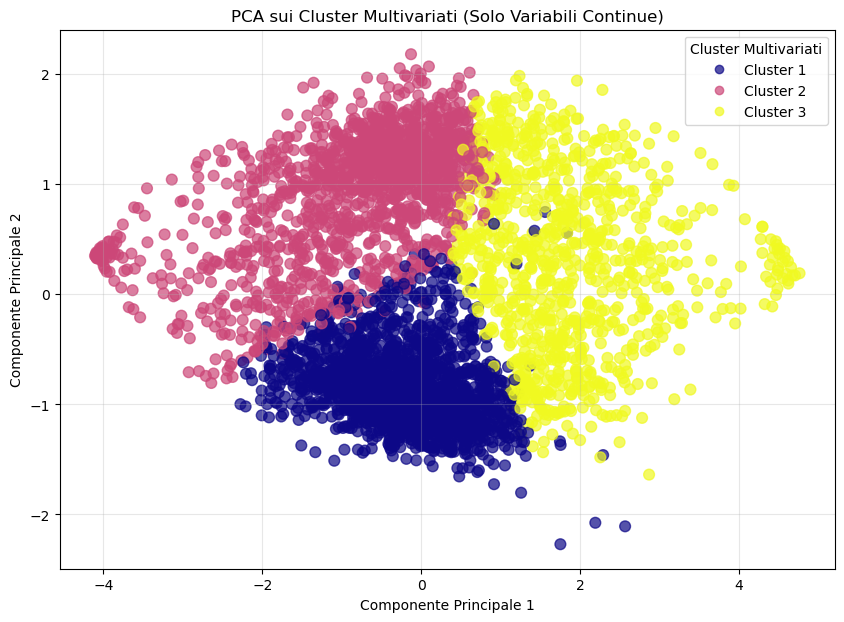

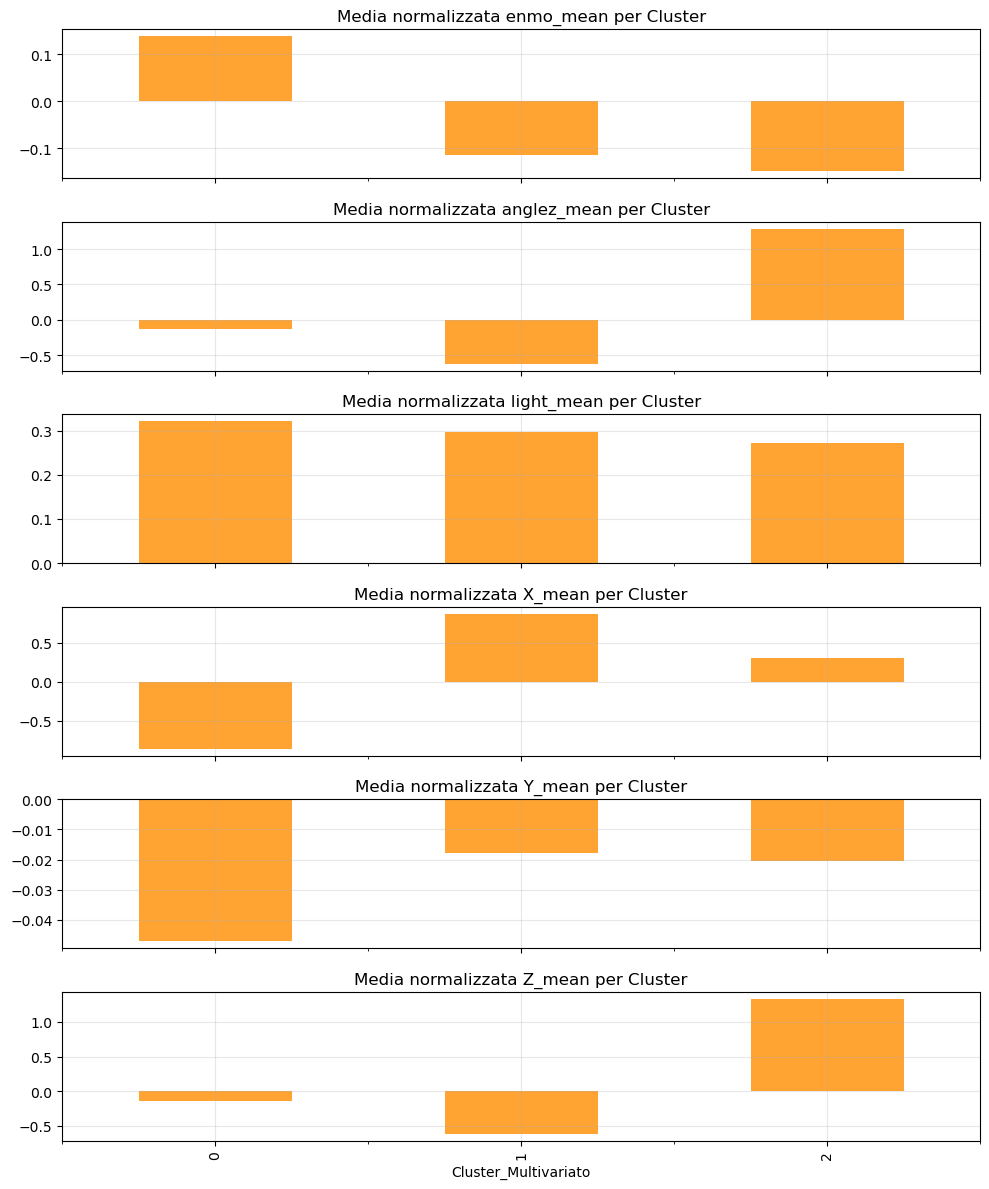

In [20]:
print("Caricamento dataset normalizzato dataset-wise...")
# CARICHIAMO IL NUOVO DATASET GIA' NORMALIZZATO
ts_raw_data = pd.read_pickle('ts_datasetwise_normalized.pkl.gz')

motif_features_list = []

# Usiamo la prima feature della lista come ancora temporale
anchor_feature = target_features[0]
print(f"Estrazione contesto multivariato ancorato sui Motif trovati su '{anchor_feature}'...")

for i, ts_df in enumerate(subset_ts):
    ts_val = ts_df[anchor_feature].values.astype(np.float64)
    if len(ts_val) <= m: continue
        
    mp_local = stumpy.stump(ts_val, m)
    # Estraiamo il primo motif
    m_idx = np.argmin(mp_local[:, 0])
    
    motif_raw_df = ts_raw_data[i].iloc[m_idx : m_idx + m]
    
    features = {
        'enmo_mean': motif_raw_df['enmo'].mean(),
        'anglez_mean': motif_raw_df['anglez'].mean(),
        'light_mean': motif_raw_df['light'].mean(),
        'X_mean': motif_raw_df['X'].mean(),
        'Y_mean': motif_raw_df['Y'].mean(),
        'Z_mean': motif_raw_df['Z'].mean(),
        'sii_binary': motif_raw_df['sii_binary'].iloc[0] # Variabile Target (NON usata per clustering)
    }
    motif_features_list.append(features)

df_motif_features = pd.DataFrame(motif_features_list)

cols_to_drop = ['sii_binary']
X_cluster = df_motif_features.drop(columns=cols_to_drop)

X_cluster = X_cluster.astype(float)

print(f"\nEsecuzione KMeans Multivariato SENZA Variabili Categoriche (K={k_clusters_multi})...")
kmeans_multi = KMeans(n_clusters=k_clusters_multi, random_state=42)
multi_clusters = kmeans_multi.fit_predict(X_cluster)

# Aggiungiamo i cluster al dataframe per l'analisi
df_motif_features['Cluster_Multivariato'] = multi_clusters

print("\n--- PROFILO DEI CLUSTER: MEDIE NUMERICHE ---")
cluster_profiles = df_motif_features.groupby('Cluster_Multivariato').mean()
display(cluster_profiles)

print("\n--- INTERPRETAZIONE DEI CLUSTER MULTIVARIATI ---")
for i, row in cluster_profiles.iterrows():
    print(f"- Cluster {i+1}:")
    print(f"   * Attività media (enmo norm.): {row['enmo_mean']:.4f}")
    print(f"   * Inclinazione media polso (anglez norm.): {row['anglez_mean']:.2f}")
    print(f"   * Luce ambientale media (norm.): {row['light_mean']:.3f}")
    print(f"   * Correlazione con Problematic Internet Use: {row['sii_binary']*100:.1f}% di casi problematici.")

# Visualizzazione PCA Multivariata
print("\nGenerazione PCA Multivariata...")
pca_multi = PCA(n_components=2)
X_pca_multi = pca_multi.fit_transform(X_cluster)
plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca_multi[:, 0], X_pca_multi[:, 1], c=multi_clusters, cmap='plasma', alpha=0.7, s=60)
handles, _ = scatter.legend_elements()
plt.legend(handles, [f"Cluster {i+1}" for i in range(k_clusters_multi)], title="Cluster Multivariati")
plt.title(f"PCA sui Cluster Multivariati (Solo Variabili Continue)")
plt.xlabel("Componente Principale 1")
plt.ylabel("Componente Principale 2")
plt.grid(True, alpha=0.3)
plt.show()

# Grafici a Barre (solo numeriche continue)
numeric_cols = ['enmo_mean', 'anglez_mean', 'light_mean', 'X_mean', 'Y_mean', 'Z_mean']
fig, axs = plt.subplots(len(numeric_cols), 1, figsize=(10, 12), sharex=True)
for j, col in enumerate(numeric_cols):
    cluster_profiles[col].plot(kind='bar', ax=axs[j], color='darkorange', alpha=0.8)
    axs[j].set_title(f'Media normalizzata {col} per Cluster')
    axs[j].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Analisi Comparativa: Shapelet
Estrae gli Shapelet sulla base di `target_feature` usando il numero definito `n_shapelets`.


In [16]:

for target_feature in target_features:
    print(f"\n{'='*50}\nESTRAZIONE SHAPELETS SULLA FEATURE: {target_feature}\n{'='*50}\n")
    
    X_train = []
    y_train = []
    for ts_df in subset_ts:
        X_train.append(ts_df[target_feature].values)
        y_train.append(ts_df['sii_binary'].iloc[0]) 

    try:
        print(f"Estrazione di {n_shapelets} Shapelet...")
        X_train_ts = to_time_series_dataset(X_train)
        shapelet_clf = ShapeletModel(n_shapelets_per_size={m: n_shapelets}, optimizer="sgd", weight_regularizer=.01, max_iter=50, random_state=42)
        shapelet_clf.fit(X_train_ts, y_train)

        fig, axs = plt.subplots(n_shapelets, 1, figsize=(10, 6), sharex=True)
        for i, shapelet in enumerate(shapelet_clf.shapelets_):
            axs[i].plot(shapelet, color='purple', linewidth=2)
            axs[i].set_title(f'Shapelet {i+1} su {target_feature} (Lunghezza {h_str})')
            axs[i].grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
    except Exception as e:
        print(f"Shapelets saltati per {target_feature}: {e}")



ESTRAZIONE SHAPELETS SULLA FEATURE: enmo

Estrazione di 3 Shapelet...
Shapelets saltati per enmo: name 'to_time_series_dataset' is not defined

ESTRAZIONE SHAPELETS SULLA FEATURE: anglez

Estrazione di 3 Shapelet...
Shapelets saltati per anglez: name 'to_time_series_dataset' is not defined
